In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

2024-06-21 16:45:39.789647: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-06-21 16:45:39.870515: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-06-21 16:45:39.870581: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-06-21 16:45:39.872691: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-06-21 16:45:39.884811: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-06-21 16:45:39.885914: I tensorflow/core/platform/cpu_feature_guard.cc:1

## Params

In [3]:
meta_neuron_array = np.arange(93)[::5] + 3
N_training_repeats = 10
cg_params = {
    "order": 1,
}
critic_params = {
    "hidden_dim": 32,
    "embed_dim": 30,
    "layers": 2,
    "activation": "tanh",
}
opt_params = {"track_quantities": False, "quiet": True, "iterations": 1}
mi_measurement_params = {'quiet':True, 'batch_size':500, 'N_batches':500}

V_width = 7
V_E_buffer = 0
E_width = 1

train_fraction = 0.5
samp_keep = 1
# neuron_inds = np.sort(sample(list(np.arange(93)), k=50))
neuron_inds = range(93)

# Put variable names here for parameters we want saved.
experiment_configuration_variables = {'mi_measurement_params','meta_neuron_array', 'N_training_repeats', 'cg_params', 'critic_params', 'opt_params', 'V_width', 'V_E_buffer', 'E_width', 'train_fraction', 'samp_keep', 'neuron_inds'}

In [4]:
meta_neuron_array

array([ 3,  8, 13, 18, 23, 28, 33, 38, 43, 48, 53, 58, 63, 68, 73, 78, 83,
       88, 93])

## Prepare data (nat scenes)

In [5]:
data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
D = ds.DataNatScenes(data_path, mov_ind=4)
print(f'current stimulus is {D.movname}')
mov_ind = D.mov_ind
mov_name = D.movname
stim = mov_name
experiment_configuration_variables.update({'mov_ind','mov_name'})

current stimulus is opticflow


## Prepare data (bar)

In [6]:
# data_path = os.path.join(project_folder, 'data', 'bar_stim_data')
# D = ds.DataBar(data_path)
# stim = "bar"
# mov_name = "bar"
# experiment_configuration_variables.add("mov_name")

In [7]:
D.reset()
D.trim(20)  # remove first 20 frames from each trial
D.subset_features(neuron_inds) 
V, E = D.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep=samp_keep)

## Run analysis

In [8]:
experiment_dims = (len(meta_neuron_array), N_training_repeats)
mi_averages_test = np.zeros(experiment_dims)
mi_averages_train = np.zeros(experiment_dims)
mi_stdevs_train = np.zeros(experiment_dims)
mi_stdevs_test = np.zeros(experiment_dims)

coarse_grainer_array = np.zeros(experiment_dims, dtype=object)
critic_function_array = np.zeros(experiment_dims, dtype=object)
train_points = np.zeros(experiment_dims, dtype=object)
test_points = np.zeros(experiment_dims, dtype=object)


for i, N_meta_neurons in tqdm(enumerate(meta_neuron_array)):
    for training_repeat in range(N_training_repeats):
        coarse_grainer = mds.PolynomialLayer(output_dim=N_meta_neurons, **cg_params)
        critic_function = mds.SeparableCritic(**critic_params)

        # make training and test subsets
        V.reset()
        E.reset()
        current_train_points, current_test_points = tools.generate_train_test_indices(
            V.P, train_fraction
        )
        V.subset_points(current_train_points)
        E.subset_points(current_train_points)
        train_points[i, training_repeat] = current_train_points
        test_points[i, training_repeat] = current_test_points

        # Train current
        als.IB(
            X=V.X,
            Y=E.X,
            coarse_grainer=coarse_grainer,
            critic_function=critic_function,
            **opt_params
        )

        # Measure InfoNCE for train
        T_train = coarse_grainer(V.X.T).numpy().T
        mi_train = als.MI_NCE(
            X=T_train, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_train[i, training_repeat] = mi_train["mi"]
        mi_stdevs_train[i, training_repeat] = mi_train["mi_stdev"]

        # Measure InfoNCE for test
        V.reset()
        E.reset()
        V.subset_points(current_test_points)
        E.subset_points(current_test_points)
        T_test = coarse_grainer(V.X.T).numpy().T
        mi_test = als.MI_NCE(
            X=T_test, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_test[i, training_repeat] = mi_test["mi"]
        mi_stdevs_test[i, training_repeat] = mi_test["mi_stdev"]

        coarse_grainer_array[i, training_repeat] = coarse_grainer
        critic_function_array[i, training_repeat] = critic_function

0it [00:00, ?it/s]

2024-06-21 16:45:48.032484: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2024-06-21 16:45:48.033894: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2256] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


19it [46:10, 145.83s/it]


In [9]:
stim = mov_name

## Save

In [10]:
save_directory = os.path.join(cur_directory, 'saved', stim)
print(f"will save to {save_directory}")

will save to /home/adam/Documents/projects/retina-past-future-ib/analyses/IB curves/saved/opticflow


In [11]:
# select variables
coarse_grainer_type = type(coarse_grainer_array[0,0])
critic_type = type(coarse_grainer_array[0,0])
save_vars = {'mi_averages_train', 'mi_averages_test', 'mi_stdevs_train', 'mi_stdevs_test', 'coarse_grainer_type', 'critic_type'}.union(experiment_configuration_variables)
local_dict = locals()
output_data = {k:local_dict[k] for k in save_vars}

In [12]:
# save things
timestamp = strftime("%Y.%m.%d %Hh %Mm %Ss.dat",gmtime())
# full_file_path = os.path.join(save_directory, '', strftime("%Y.%m.%d %Hh %Mm %Ss",gmtime())+'.dat')
full_file_path = os.path.join(save_directory, '(7,0,1).dat')
# full_file_path = os.path.join(save_directory, 'test.dat')
os.makedirs(os.path.dirname(full_file_path), exist_ok=True)
with open(full_file_path, 'wb+') as f:
            pickle.dump(output_data, f)

## Reload and plot

In [21]:
load_path = project_folder + 'analyses/IB curves/saved/opticflow/(4,0,1).dat'
# load_path = project_folder + 'analyses/IB curves/saved/test.dat'
with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)

FileNotFoundError: [Errno 2] No such file or directory: project_folder + 'analyses/IB curves/saved/opticflow/(4,0,1).dat'

In [ ]:
data_dict.keys()

dict_keys(['V_E_buffer', 'N_training_repeats', 'mi_stdevs_train', 'mi_averages_test', 'critic_type', 'samp_keep', 'neuron_inds', 'mi_averages_train', 'mov_name', 'mi_measurement_params', 'critic_params', 'coarse_grainer_type', 'mov_ind', 'V_width', 'cg_params', 'train_fraction', 'meta_neuron_array', 'mi_stdevs_test', 'E_width', 'opt_params'])

In [ ]:
average_test = np.average(data.mi_averages_test, axis=1)
average_train = np.average(data.mi_averages_train, axis=1)
trial_variance_test = np.diag(np.cov(data.mi_averages_test))
trial_variance_train = np.diag(np.cov(data.mi_averages_train))
full_stdevs_train = np.sqrt(np.sum(data.mi_stdevs_train**2, axis=1) + trial_variance_train)
full_stdevs_test = np.sqrt(np.sum(data.mi_stdevs_test**2, axis=1) + trial_variance_test)

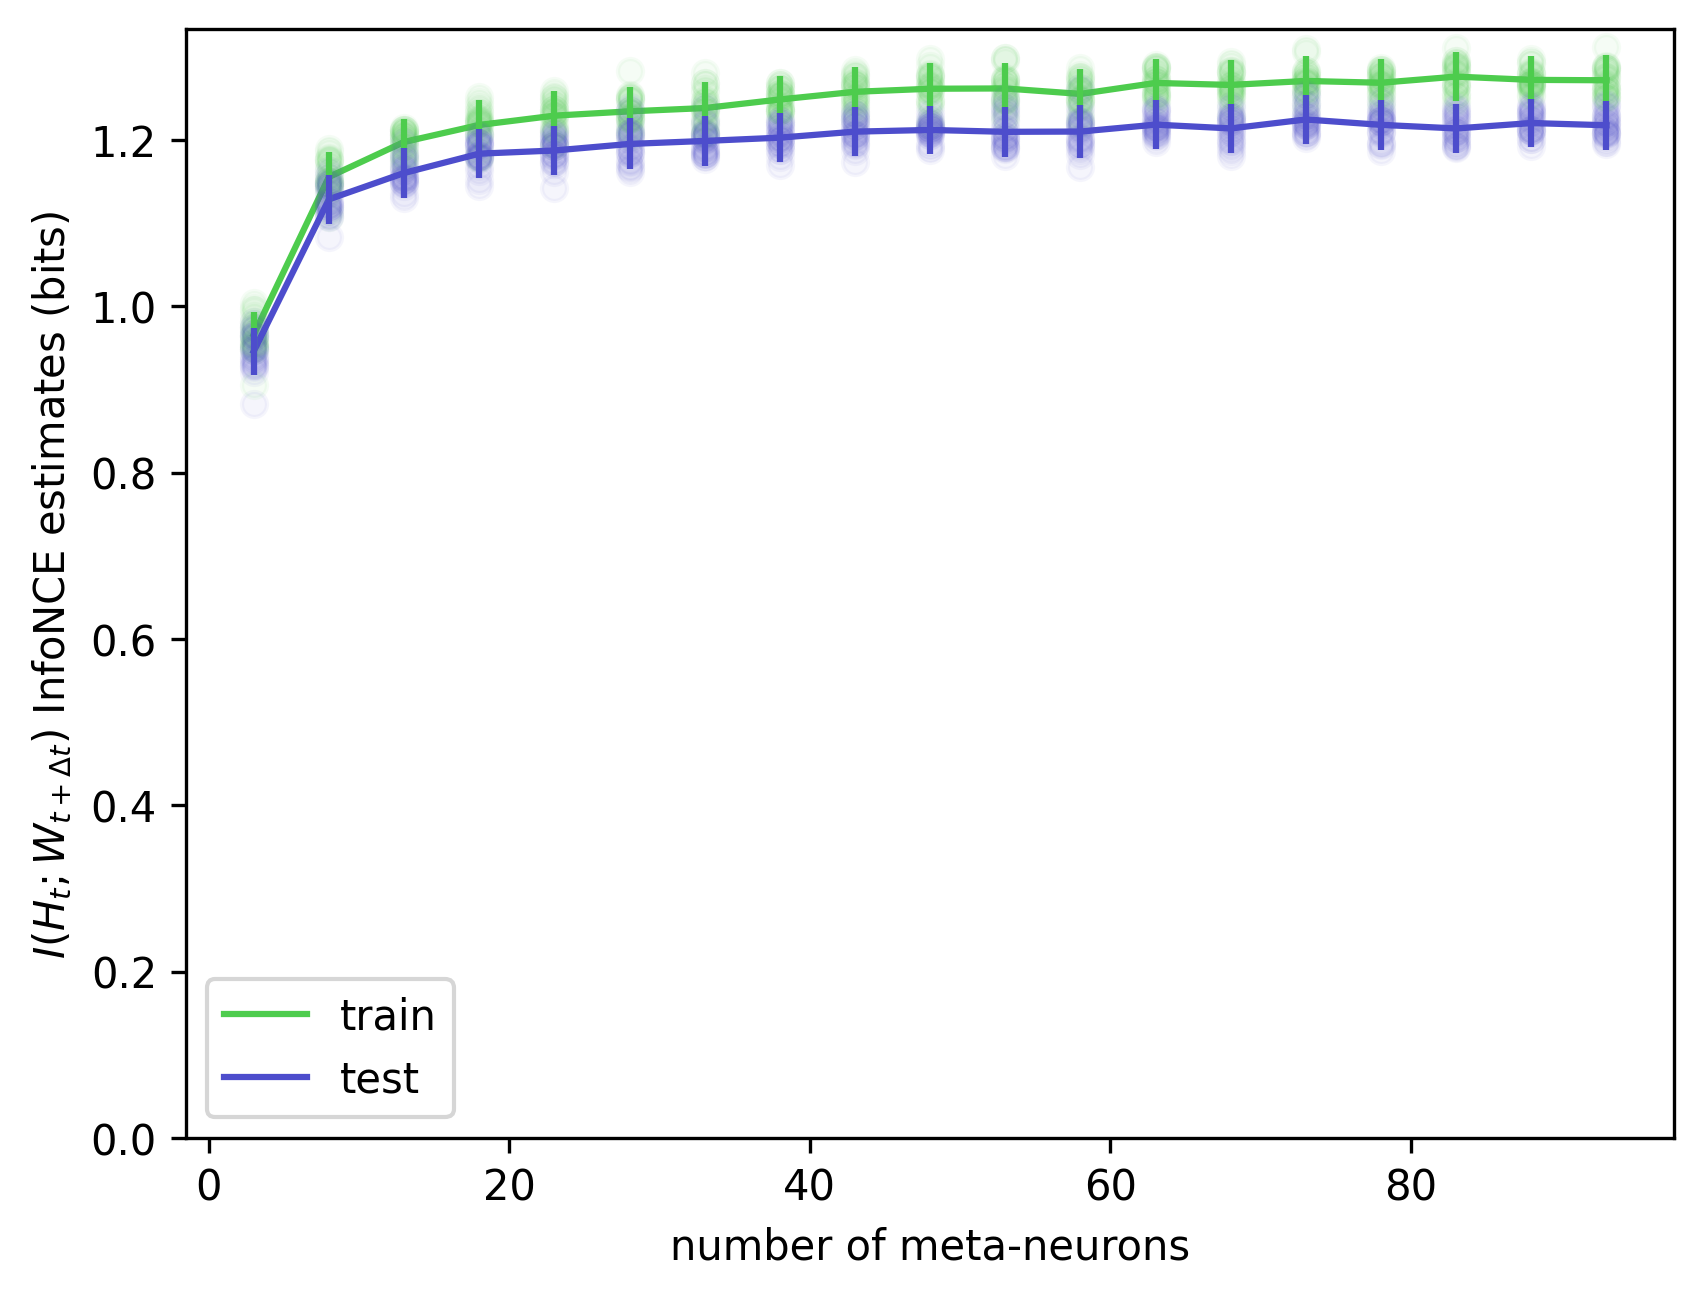

In [22]:
x = data.meta_neuron_array

c1 = 0.3
c2 = 0.8
alp = 0.05
plt.figure(dpi=300)
plt.plot(x, average_train/np.log(2), color=(c1,c2,c1), label='train')
plt.plot(x, data.mi_averages_train/np.log(2),'o', color=(c1,c2,c1,alp))
plt.plot(x, average_test/np.log(2), color=(c1,c1,c2), label='test');
plt.plot(x, data.mi_averages_test/np.log(2),'o', color=(c1,c1,c2,alp))
plt.errorbar(x, average_train/np.log(2), yerr=full_stdevs_train, linestyle='', color=(c1,c2,c1))
plt.errorbar(x, average_test/np.log(2), yerr=full_stdevs_test, linestyle='', color=(c1,c1,c2))
plt.ylim(ymin=0)
# plt.title('Predictive info quickly saturates at a few meta-neurons')
plt.xlabel('number of meta-neurons')
plt.ylabel(r'$I(H_{t};W_{t+\Delta t})$ InfoNCE estimates (bits)')
plt.legend();

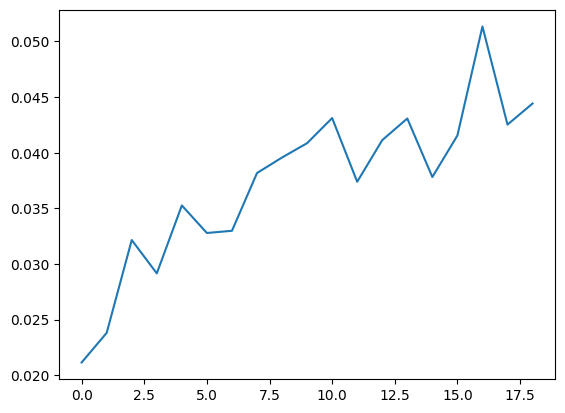

In [ ]:
plt.plot((average_train - average_test) / average_test)